In [18]:
import sys
sys.path.append('../../')

import matplotlib.pyplot as plt

# Import methods
import QGP.Defocusing.Methods as Def
import QGP.Focusing.Methods as Foc
from QGP.Soliton_Gen import *
from Utilities import *
import scipy.sparse as sp

import config

## Dark

In [2]:
# Create solitons
L = 20
N = 5_001
k = 1/4

pars = {"k":k}

c_1 = 0
c_2 = np.sqrt(2)/2
c_3 = 0.1

# Theretical solitons
w_dark, x_dark = soliton(c_2, k, soliton_type="dark", L=L, N=N, as_func=True) #c=0

Creating soliton...
Soliton created


In [3]:
#path = "test/"
Nt = 500
tf = 10

w_comp = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_comp.set_init_condition(w_dark)
w_comp.solve(method="fixed point")

Iteration  1  of  500 . Fixed point Error:  6.961304839795115e-13 . Total iteration:  7
Iteration  2  of  500 . Fixed point Error:  8.015111864661421e-13 . Total iteration:  7
Iteration  3  of  500 . Fixed point Error:  1.9560614388831605e-13 . Total iteration:  8
Iteration  4  of  500 . Fixed point Error:  5.125421659291241e-13 . Total iteration:  8
Iteration  5  of  500 . Fixed point Error:  3.148105993770055e-13 . Total iteration:  9
Iteration  6  of  500 . Fixed point Error:  7.07366673841008e-13 . Total iteration:  9
Iteration  7  of  500 . Fixed point Error:  3.667174265137492e-13 . Total iteration:  10
Iteration  8  of  500 . Fixed point Error:  6.663559990148393e-13 . Total iteration:  10
Iteration  9  of  500 . Fixed point Error:  3.2622362375659817e-13 . Total iteration:  11
Iteration  10  of  500 . Fixed point Error:  5.096413928495346e-13 . Total iteration:  11
Iteration  11  of  500 . Fixed point Error:  7.449222662984149e-13 . Total iteration:  11
Iteration  12  of  500 .

MovieWriter ffmpeg unavailable; using Pillow instead.


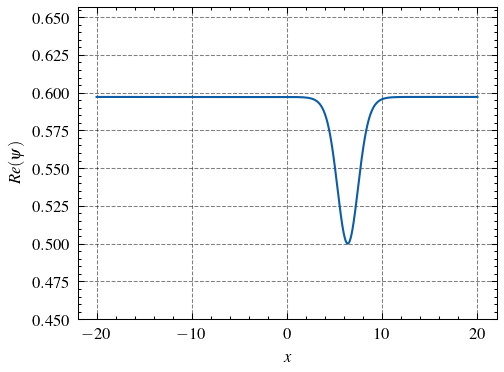

In [4]:
w_comp.animate_solution("test.gif", 50, auto_adjust=False, coord="real")

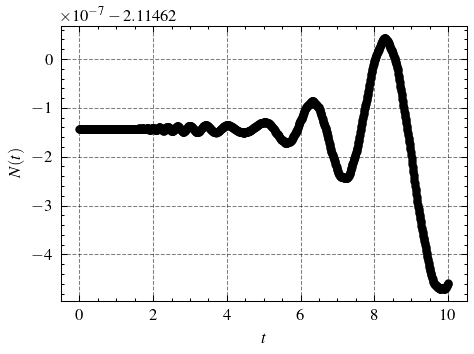

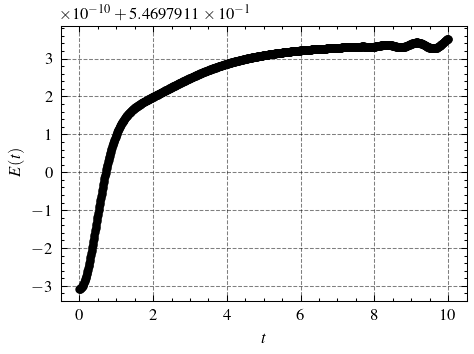

In [7]:
w_mass = w_comp.get_mass(plot=True)
w_energy = w_comp.get_energy(plot=True)

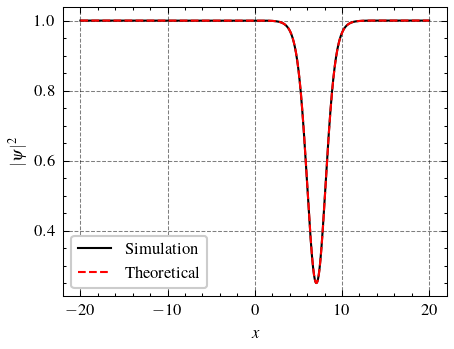

In [5]:
w_comp.plot(tf, label="Simulation")
plt.plot(x_dark, norm(w_dark(x_dark-c_2*tf)), label="Theoretical")
plt.legend()
plt.show()

## Bright

In [2]:
L = 40
N = 5_000 #15_001
k = 1/4

pars = {"k":k}
c = np.sqrt(2)/2
w = 1 #np.sqrt(2)/2

w_bright, x_bright = soliton(c, k, w=w, soliton_type="bright", L=L, N=N+1, as_func=True)

Creating soliton...
Soliton created


In [3]:
tf = 10
Nt = 160 

w_comp = Foc.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_comp.set_init_condition(w_bright)
w_comp.solve()#method="fixed point")

Iteration  1  of  160 . Error:  2.4037673765562857e-13 . Newton iterations:  11
Iteration  2  of  160 . Error:  3.8357118462903005e-13 . Newton iterations:  11
Iteration  3  of  160 . Error:  7.623944377276444e-13 . Newton iterations:  11
Iteration  4  of  160 . Error:  1.3694753728204872e-13 . Newton iterations:  12
Iteration  5  of  160 . Error:  2.919612856747328e-13 . Newton iterations:  12
Iteration  6  of  160 . Error:  5.6209922318338e-13 . Newton iterations:  12
Iteration  7  of  160 . Error:  9.313590521665228e-13 . Newton iterations:  12
Iteration  8  of  160 . Error:  1.4330569793926657e-13 . Newton iterations:  13
Iteration  9  of  160 . Error:  3.158387183841437e-13 . Newton iterations:  13
Iteration  10  of  160 . Error:  1.787854851076441e-13 . Newton iterations:  14
Iteration  11  of  160 . Error:  6.185308207108699e-13 . Newton iterations:  14
Iteration  12  of  160 . Error:  2.830715956690209e-13 . Newton iterations:  15
Iteration  13  of  160 . Error:  7.242592638178

MovieWriter ffmpeg unavailable; using Pillow instead.


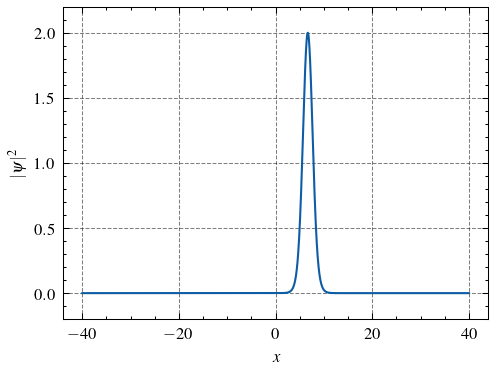

In [4]:
w_comp.animate_solution("test.gif", 10)

In [5]:
def bright_soliton(x, t, c=c, w=w):
    i = 1j
    output = w_bright(x-c*t) * np.exp(i*(c**2/4*t-c/2*x-w*t))
    return output

w_comp.w_theo = bright_soliton
error = w_comp.get_error()

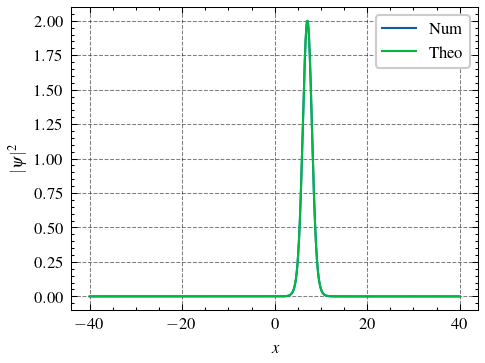

In [6]:
w_comp.plot(tf, label="Num")
plt.plot(x_bright, norm(bright_soliton(x_bright, tf)), label="Theo")
plt.legend()
plt.show()

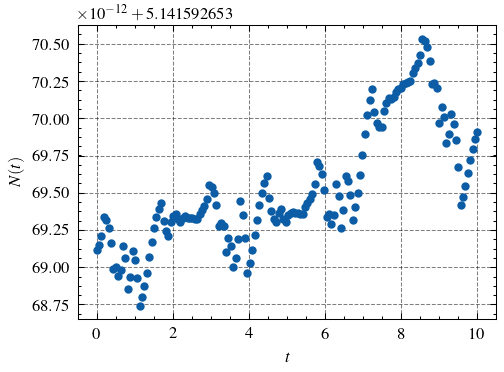

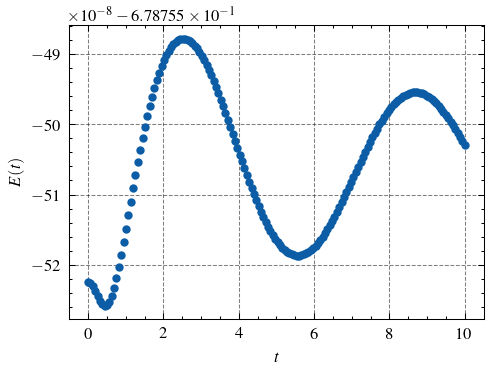

In [7]:
w_mass = w_comp.get_mass(plot=True)
w_energy = w_comp.get_energy(plot=True)

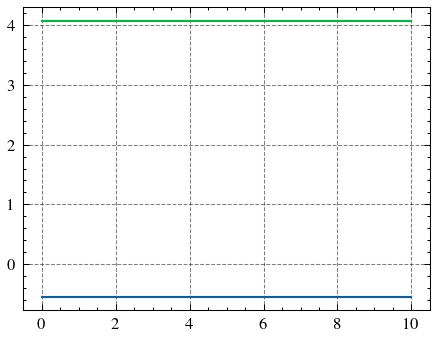

In [7]:
plt.plot(w_comp.t, w_energy)
plt.plot(w_comp.t, w_mass)
#plt.ylim(1.3, 1.6)
plt.show()

## Gaussian init conditions

In [2]:
A = 0.65
sigma = 1/10
def gaussian(x):
    output = A * np.exp(-x**2/(2 * sigma**2))
    return output

In [3]:
L = np.pi
N = 10_000
k = 1
Nt = 10_000
tf = 2.25e-3
pars = {"k":k}

w_gauss = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_gauss.set_init_condition(gaussian)
w_gauss.solve()#method="fixed point")

Iteration  1  of  10000 . Newton Error:  1.3613445247858352e-15 . Total iteration:  2
Iteration  2  of  10000 . Newton Error:  1.361542386651539e-15 . Total iteration:  2
Iteration  3  of  10000 . Newton Error:  1.3615315148126307e-15 . Total iteration:  2
Iteration  4  of  10000 . Newton Error:  1.3615662025325179e-15 . Total iteration:  2
Iteration  5  of  10000 . Newton Error:  1.3613598613254095e-15 . Total iteration:  2
Iteration  6  of  10000 . Newton Error:  1.361611623243994e-15 . Total iteration:  2
Iteration  7  of  10000 . Newton Error:  1.3614444585009133e-15 . Total iteration:  2
Iteration  8  of  10000 . Newton Error:  1.3615688728871691e-15 . Total iteration:  2
Iteration  9  of  10000 . Newton Error:  1.3616009143455903e-15 . Total iteration:  2
Iteration  10  of  10000 . Newton Error:  1.3615436268334267e-15 . Total iteration:  2
Iteration  11  of  10000 . Newton Error:  1.3617207711814206e-15 . Total iteration:  2
Iteration  12  of  10000 . Newton Error:  1.3613458630

In [4]:
N_2 = 5_000

w_gauss_N_2 = Def.CNFD(L, N_2, Nt, tf, pars, "neumann", order=2)
w_gauss_N_2.set_init_condition(gaussian)
w_gauss_N_2.solve()

Iteration  1  of  10000 . Newton Error:  1.3597171465672791e-15 . Total iteration:  2
Iteration  2  of  10000 . Newton Error:  1.3597048735426514e-15 . Total iteration:  2
Iteration  3  of  10000 . Newton Error:  1.359705875609956e-15 . Total iteration:  2
Iteration  4  of  10000 . Newton Error:  1.3597190246547102e-15 . Total iteration:  2
Iteration  5  of  10000 . Newton Error:  1.3597393124938187e-15 . Total iteration:  2
Iteration  6  of  10000 . Newton Error:  1.3597374431492824e-15 . Total iteration:  2
Iteration  7  of  10000 . Newton Error:  1.3597366954762599e-15 . Total iteration:  2
Iteration  8  of  10000 . Newton Error:  1.3597100344192425e-15 . Total iteration:  2
Iteration  9  of  10000 . Newton Error:  1.3597919444439854e-15 . Total iteration:  2
Iteration  10  of  10000 . Newton Error:  1.3597548496011172e-15 . Total iteration:  2
Iteration  11  of  10000 . Newton Error:  1.3597072215358943e-15 . Total iteration:  2
Iteration  12  of  10000 . Newton Error:  1.359743391

In [9]:
e_gauss = w_gauss.get_energy(background=0)
e_gauss_N_2 = w_gauss_N_2.get_energy(background=0)

In [12]:
mass_gauss = w_gauss.get_mass()
mass_gauss_N_2 = w_gauss_N_2.get_mass()

In [13]:
save_file(mass_gauss, "mass_N_10000")
save_file(mass_gauss_N_2, "mass_N_5000")

In [5]:
w_gauss_max = np.abs(w_gauss.w).max(axis=1)
w_gauss_max_N_2 = np.abs(w_gauss_N_2.w).max(axis=1)

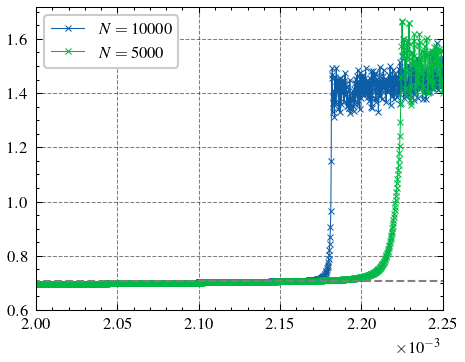

In [8]:
plt.plot(w_gauss.t, w_gauss_max, "x-", lw=.5, markeredgewidth=.5, ms=3, label=r"$N=10000$")
plt.plot(w_gauss_N_2.t, w_gauss_max_N_2, "x-", lw=.5, markeredgewidth=.5, ms=3, label=r"$N=5000$")
plt.hlines(np.sqrt(2)/2, 0, w_gauss.t[-1], color="gray", ls="--")
plt.ticklabel_format(style='sci',scilimits=(-3,4),axis="x")
plt.xlim(2e-3, 2.25e-3)
plt.legend()
#plt.ylim(0.65, 1)
#plt.savefig("gaussian.pdf", dpi=300, bbox_inches = "tight")
plt.show()

# Other tests